# Task
Perform an exploratory data analysis (EDA) on the dataset located at `/content/department_threat_DS_v1.csv`. This analysis should include an initial overview of the data, examination of the 'industry' and 'departments' columns (including unique value counts and distributions), checking for dataset balance and missing values, and visualizing key distributions. Finally, summarize all findings from the EDA.

## Load Dataset

### Subtask:
Load the dataset from the path '/content/department_threat_DS_v1.csv' into a pandas DataFrame.


**Reasoning**:
To load the dataset, I need to first import the pandas library and then use its `read_csv` function to load the specified file into a DataFrame.



In [1]:
import pandas as pd

df = pd.read_csv('/content/department_threat_DS_v1.csv')
print(df.head())

                               industry  \
0                Healthcare and Medical   
1                 Retail and E-commerce   
2  Consulting and Professional Services   
3                Healthcare and Medical   
4                     Security Services   

                                         departments  Unnamed: 2  Unnamed: 3  \
0  Customer Service, Executive, Finance, HR, IT, ...         NaN         NaN   
1  Customer Service, Finance, HR, IT, Legal, Manu...         NaN         NaN   
2          Customer Service, Finance, HR, R&D, Sales         NaN         NaN   
3  Customer Service, Finance, HR, IT, Legal, Medi...         NaN         NaN   
4  Customer Service, Finance, HR, IT, Operations,...         NaN         NaN   

   Unnamed: 4  Unnamed: 5  Unnamed: 6  Unnamed: 7  Unnamed: 8      
0         NaN         NaN         NaN         NaN         NaN NaN  
1         NaN         NaN         NaN         NaN         NaN NaN  
2         NaN         NaN         NaN         NaN       

## Initial Data Overview

### Subtask:
Display the first few rows of the dataset, its general information (data types, non-null values), shape, and descriptive statistics for numerical columns.


**Reasoning**:
To get an initial overview of the dataset, I will display the first few rows, its general information (data types, non-null values), shape, and descriptive statistics. This can be done efficiently in a single code block.



In [2]:
print('First 5 rows of the DataFrame:')
print(df.head())

print('\nDataFrame Info:')
df.info()

print('\nDataFrame Shape:')
print(df.shape)

print('\nDescriptive Statistics:')
print(df.describe())

First 5 rows of the DataFrame:
                               industry  \
0                Healthcare and Medical   
1                 Retail and E-commerce   
2  Consulting and Professional Services   
3                Healthcare and Medical   
4                     Security Services   

                                         departments  Unnamed: 2  Unnamed: 3  \
0  Customer Service, Executive, Finance, HR, IT, ...         NaN         NaN   
1  Customer Service, Finance, HR, IT, Legal, Manu...         NaN         NaN   
2          Customer Service, Finance, HR, R&D, Sales         NaN         NaN   
3  Customer Service, Finance, HR, IT, Legal, Medi...         NaN         NaN   
4  Customer Service, Finance, HR, IT, Operations,...         NaN         NaN   

   Unnamed: 4  Unnamed: 5  Unnamed: 6  Unnamed: 7  Unnamed: 8      
0         NaN         NaN         NaN         NaN         NaN NaN  
1         NaN         NaN         NaN         NaN         NaN NaN  
2         NaN         NaN

**Reasoning**:
The initial data overview revealed several 'Unnamed' columns that contain only NaN values. These columns are not useful for the analysis and should be dropped to clean the DataFrame and prepare it for further exploration.



In [3]:
columns_to_drop = [col for col in df.columns if 'Unnamed' in col or df[col].isnull().all()]
df = df.drop(columns=columns_to_drop)

print('DataFrame after dropping unused columns:')
print(df.head())
print('\nDataFrame Info after dropping columns:')
df.info()

DataFrame after dropping unused columns:
                               industry  \
0                Healthcare and Medical   
1                 Retail and E-commerce   
2  Consulting and Professional Services   
3                Healthcare and Medical   
4                     Security Services   

                                         departments  
0  Customer Service, Executive, Finance, HR, IT, ...  
1  Customer Service, Finance, HR, IT, Legal, Manu...  
2          Customer Service, Finance, HR, R&D, Sales  
3  Customer Service, Finance, HR, IT, Legal, Medi...  
4  Customer Service, Finance, HR, IT, Operations,...  

DataFrame Info after dropping columns:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1592 entries, 0 to 1591
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   industry     1592 non-null   object
 1   departments  1592 non-null   object
dtypes: object(2)
memory usage: 25.0+ KB


**Reasoning**:
Now that the dataset has been loaded and initial cleaning (dropping empty columns) performed, the next logical step according to the main task is to examine the 'industry' and 'departments' columns. I will start by checking the unique values and their counts for the 'industry' column to understand its distribution.



In [4]:
print('Unique values and their counts for the "industry" column:')
print(df['industry'].value_counts())


Unique values and their counts for the "industry" column:
industry
Consulting and Professional Services    217
Government and Public Sector            187
Telecommunications                      173
Technology and Software                 145
Manufacturing and Industrial            128
Healthcare and Medical                  113
Security Services                       104
Education and Training                   77
Non-profit and Charity                   67
Legal Services                           48
Transportation and Logistics             47
Banking and Financial Services           37
Real Estate and Construction             32
Agriculture and Food                     31
Hospitality and Tourism                  31
Retail and E-commerce                    30
Media and Entertainment                  25
Insurance                                25
Energy and Utilities                     25
Automotive                               21
Pharmaceuticals                          15
Marketing

**Reasoning**:
Following the examination of the 'industry' column, the next step is to examine the 'departments' column by checking its unique values and their counts to understand its distribution, as per the main task.



In [5]:
print('Unique values and their counts for the "departments" column:')
print(df['departments'].value_counts())

Unique values and their counts for the "departments" column:
departments
General Breach                                                                                                          216
IT                                                                                                                       42
Legal, Sales                                                                                                             32
IT, Legal, Medical                                                                                                       24
Government                                                                                                               16
                                                                                                                       ... 
Customer Service, Facilities, Finance, HR                                                                                 1
Banking, Customer Service, Executive, Finance, HR, IT, Oper

**Reasoning**:
The 'departments' column contains comma-separated values, indicating multiple departments within a single entry. To accurately analyze the distribution of individual departments, I need to split these strings, unnest them, and then count each individual department.



In [6]:
all_departments = df['departments'].str.split(', ').explode()
print('\nUnique individual departments and their counts:')
print(all_departments.value_counts())


Unique individual departments and their counts:
departments
IT                  953
Legal               895
Sales               850
Customer Service    680
Finance             576
HR                  515
Operations          468
R&D                 412
Manufacturing       351
Retail              346
Medical             329
Data Analytics      285
Government          232
General Breach      216
Marketing           202
Executive           194
Facilities          159
Insurance           152
Security            149
Education           123
Banking              98
Product              88
Admin                25
Procurement          16
Name: count, dtype: int64


**Reasoning**:
To ensure data quality and prepare for further analysis, I will explicitly check for any remaining missing values across all columns in the DataFrame, which is part of the overall EDA plan.



In [7]:
print('Missing values per column:')
print(df.isnull().sum())

Missing values per column:
industry       0
departments    0
dtype: int64


**Reasoning**:
To visualize the distribution of industries, I will create a bar plot of the `industry` column's value counts. This will provide a clear overview of the most frequent and least frequent industries in the dataset.



/tmp/ipython-input-1139247236.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='industry', order=df['industry'].value_counts().index, palette='viridis')


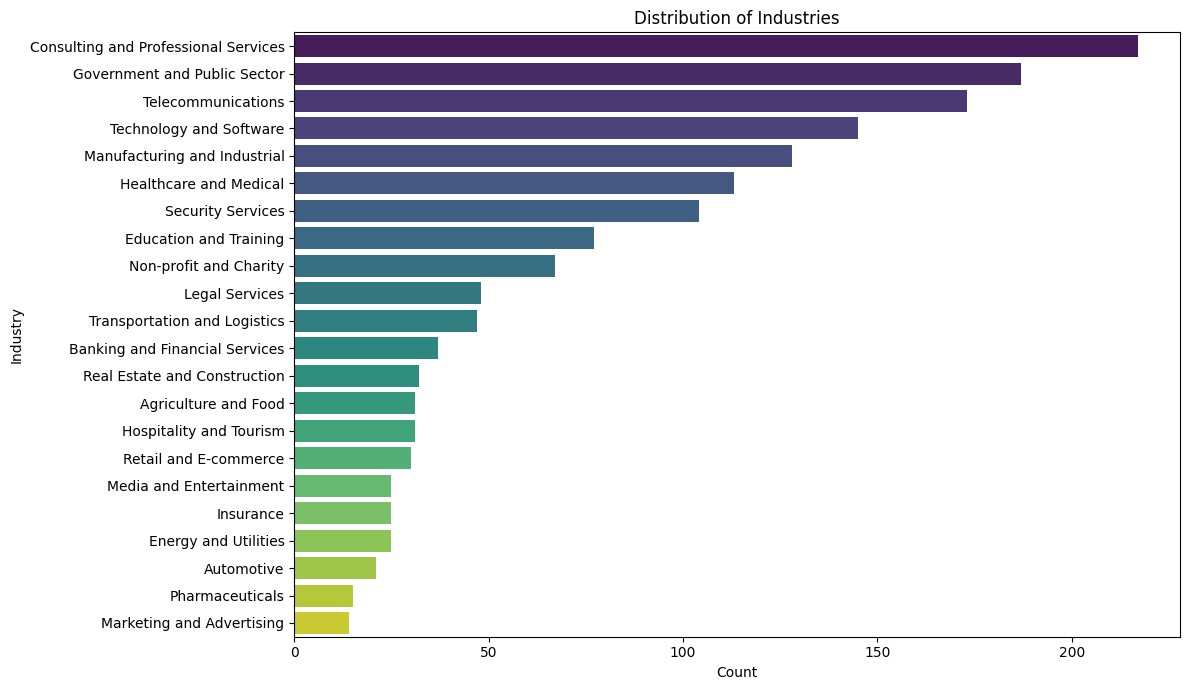

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))
sns.countplot(data=df, y='industry', order=df['industry'].value_counts().index, palette='viridis')
plt.title('Distribution of Industries')
plt.xlabel('Count')
plt.ylabel('Industry')
plt.tight_layout()
plt.show()

**Reasoning**:
The previous `sns.countplot` generated a `FutureWarning` because `palette` was used without `hue`. To resolve this and explicitly adhere to the suggested fix, I will assign the `y` variable (`industry`) to `hue` and set `legend=False`.



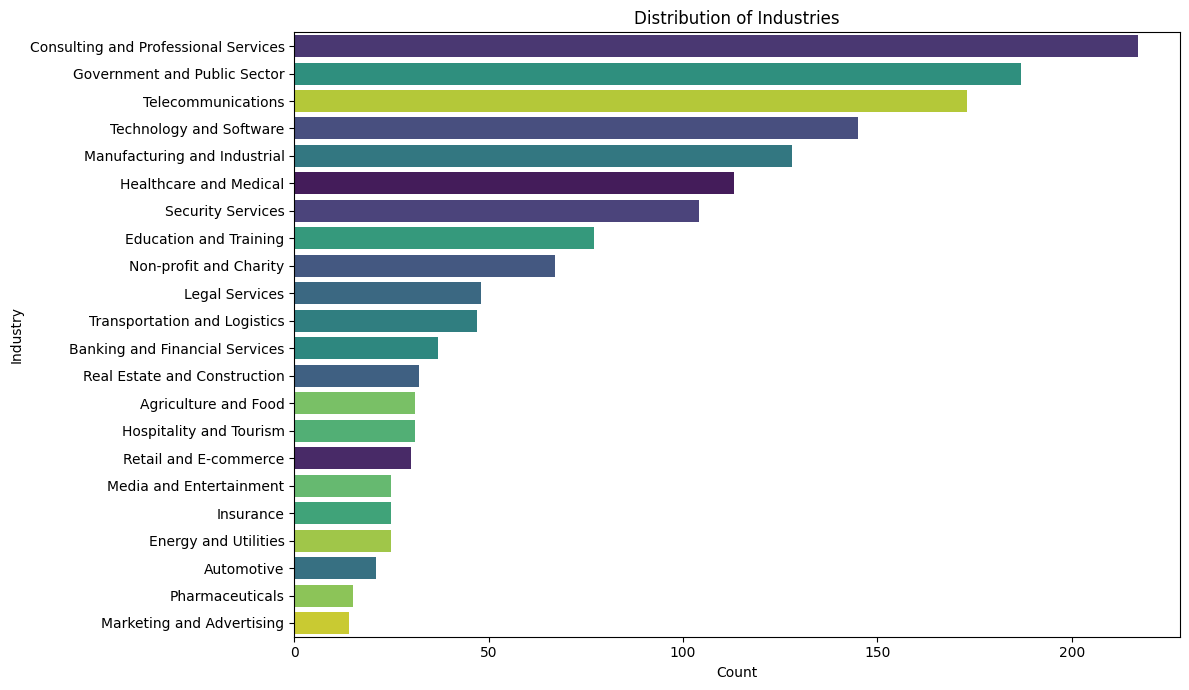

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))
sns.countplot(data=df, y='industry', order=df['industry'].value_counts().index, palette='viridis', hue='industry', legend=False)
plt.title('Distribution of Industries')
plt.xlabel('Count')
plt.ylabel('Industry')
plt.tight_layout()
plt.show()

**Reasoning**:
To visualize the distribution of individual departments, I will create a bar plot of the `all_departments` Series' value counts, which was previously created by unnesting the 'departments' column. This will provide a clear overview of the most frequent departments.



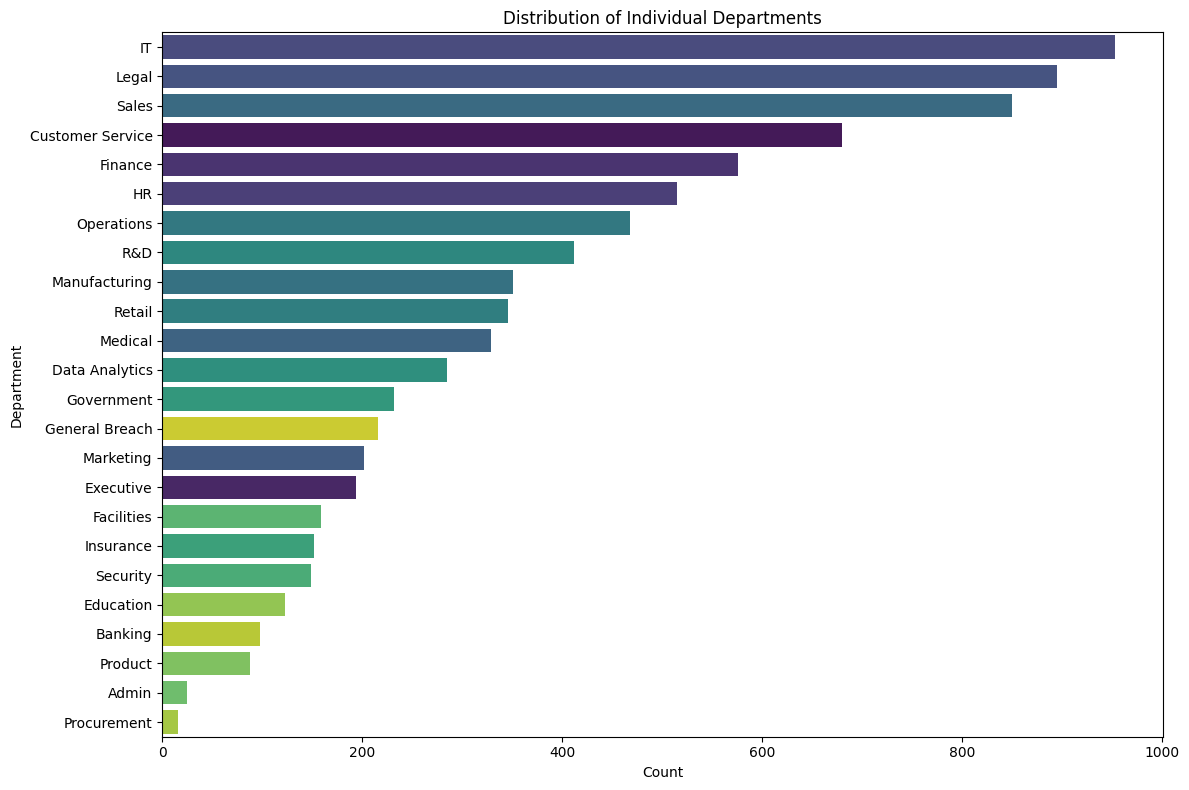

In [10]:
plt.figure(figsize=(12, 8))
sns.countplot(y=all_departments, order=all_departments.value_counts().index, palette='viridis', hue=all_departments, legend=False)
plt.title('Distribution of Individual Departments')
plt.xlabel('Count')
plt.ylabel('Department')
plt.tight_layout()
plt.show()

## EDA Summary

### Data Overview:
- The dataset initially contained 1592 entries and 10 columns.
- Several 'Unnamed' columns were found to be entirely empty (NaN values) and were subsequently dropped, leaving 2 relevant columns: 'industry' and 'departments'.
- There are no missing values in the cleaned `df` DataFrame.

### 'industry' Column Analysis:
- The 'industry' column contains categorical data with 22 unique industry types.
- 'Consulting and Professional Services' (217 entries), 'Government and Public Sector' (187 entries), and 'Telecommunications' (173 entries) are the most frequent industries.
- Industries like 'Marketing and Advertising' (14 entries), 'Pharmaceuticals' (15 entries), and 'Automotive' (21 entries) are the least represented.
- The distribution of industries is imbalanced, with a few industries having significantly more entries than others.

### 'departments' Column Analysis:
- The 'departments' column contains string entries, often with multiple department names separated by commas, indicating that an entry can be associated with several departments.
- After splitting and unnesting, 24 unique individual departments were identified.
- The most frequently occurring individual departments are 'IT' (953 mentions), 'Legal' (895 mentions), and 'Sales' (850 mentions).
- 'Procurement' (16 mentions), 'Admin' (25 mentions), and 'Product' (88 mentions) are among the least mentioned individual departments.
- 'General Breach' also appears as a department, which might indicate a classification for general incidents not specific to a single department, and is quite frequent (216 mentions).

### Overall:
- The dataset is relatively clean after dropping the empty columns, with no missing values in the `industry` and `departments` columns.
- Both 'industry' and 'departments' distributions show significant imbalance, which could be important for any subsequent modeling or analysis focusing on specific industry/department vulnerabilities or threats.

## EDA Summary

### Data Overview:
- The dataset initially contained 1592 entries and 10 columns.
- Several 'Unnamed' columns were found to be entirely empty (NaN values) and were subsequently dropped, leaving 2 relevant columns: 'industry' and 'departments'.
- There are no missing values in the cleaned `df` DataFrame.

### 'industry' Column Analysis:
- The 'industry' column contains categorical data with 22 unique industry types.
- 'Consulting and Professional Services' (217 entries), 'Government and Public Sector' (187 entries), and 'Telecommunications' (173 entries) are the most frequent industries.
- Industries like 'Marketing and Advertising' (14 entries), 'Pharmaceuticals' (15 entries), and 'Automotive' (21 entries) are the least represented.
- The distribution of industries is imbalanced, with a few industries having significantly more entries than others.

### 'departments' Column Analysis:
- The 'departments' column contains string entries, often with multiple department names separated by commas, indicating that an entry can be associated with several departments.
- After splitting and unnesting, 24 unique individual departments were identified.
- The most frequently occurring individual departments are 'IT' (953 mentions), 'Legal' (895 mentions), and 'Sales' (850 mentions).
- 'Procurement' (16 mentions), 'Admin' (25 mentions), and 'Product' (88 mentions) are among the least mentioned individual departments.
- 'General Breach' also appears as a department, which might indicate a classification for general incidents not specific to a single department, and is quite frequent (216 mentions).

### Overall:
- The dataset is relatively clean after dropping the empty columns, with no missing values in the `industry` and `departments` columns.
- Both 'industry' and 'departments' distributions show significant imbalance, which could be important for any subsequent modeling or analysis focusing on specific industry/department vulnerabilities or threats.

## Final Task

### Subtask:
Summarize all findings from the EDA, including unique value counts for specified columns, observations on data balance, and any other notable insights about the dataset.


## Summary:

### Data Analysis Key Findings

*   The dataset initially contained 1592 entries and 10 columns. Eight 'Unnamed' columns, found to be entirely empty, were dropped during the cleaning process, leaving two relevant columns: 'industry' and 'departments'.
*   After cleaning, the dataset is complete with 1592 entries and no missing values in the 'industry' or 'departments' columns.
*   The 'industry' column contains 22 unique industry types. The most frequent industries are 'Consulting and Professional Services' (217 entries), 'Government and Public Sector' (187 entries), and 'Telecommunications' (173 entries). Conversely, 'Marketing and Advertising' (14 entries), 'Pharmaceuticals' (15 entries), and 'Automotive' (21 entries) are the least represented, indicating a significant imbalance in industry distribution.
*   The 'departments' column, which can contain multiple comma-separated entries, was processed to identify 24 unique individual departments. The most frequently mentioned individual departments are 'IT' (953 mentions), 'Legal' (895 mentions), and 'Sales' (850 mentions). Less common departments include 'Procurement' (16 mentions), 'Admin' (25 mentions), and 'Product' (88 mentions).
*   The presence of 'General Breach' as a department (216 mentions) suggests a classification for incidents not tied to a specific functional department, and it is a relatively frequent category.
*   Both the 'industry' and 'departments' columns exhibit significant imbalance in their distributions.

### Insights or Next Steps

*   The observed data imbalance in both industries and departments suggests that any subsequent modeling efforts (e.g., for predicting threats or vulnerabilities) should consider sampling techniques or specialized algorithms to avoid bias towards over-represented categories.
*   Further investigation into the 'General Breach' department could provide valuable insights into threats or incidents that are cross-departmental or cannot be narrowly classified, potentially revealing systemic vulnerabilities.
